# 04 비용 · 절감액 · 가정 바꾸기 · 근무표 확정 시점

기본 가정: 부족 1명·일 60만 원(C_u), 남음 15만 원(C_o), 1명당 2,000명 → τ* = 0.8. 인력은 소수로 계산(가이드).

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager

# 묶음 폴더(real_final 또는 final) 찾기 — notebooks/ 에서 열든, 묶음 폴더나 그 위(Colab 의 /content)에서 열든 된다
HERE = Path.cwd()
CANDIDATES = [p / sub for p in [HERE, *HERE.parents] for sub in ('data', 'real_final/data', 'final/data')]
DATA = next((c for c in CANDIDATES if (c / 'metrics.csv').exists()), None)
if DATA is None:
    raise FileNotFoundError(f'data/metrics.csv 를 찾지 못했습니다 (지금 위치: {HERE}). '
                            '묶음 폴더 전체(data · notebooks ...)를 받았는지, 노트북을 notebooks/ 에서 열었는지 확인하세요.')
BASE = DATA.parent                              # 묶음 폴더
# 01 노트북만 쓰는 src/ 와 원본 데이터: 묶음 폴더 안(real_final: src/ · raw/)이 먼저, 없으면 저장소 최상위
SRC = next((p for p in [BASE / 'src', BASE.parent / 'src'] if (p / 'hv.py').exists()), None)
RAW = next((p for p in [BASE / 'raw', BASE.parent] if (p / 'anchors.json').exists()), None)
if SRC is not None:
    sys.path.insert(0, str(SRC))
print('데이터:', DATA)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 80)
HAVE = {f.name for f in font_manager.fontManager.ttflist}
KFONT = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans KR'] if f in HAVE), None)
if KFONT is None:
    print('※ 한글 폰트가 없어 그림의 한글이 네모로 보일 수 있습니다 (Colab: !apt -qq install fonts-nanum 후 런타임 다시 시작)')
plt.rcParams.update({'font.family': KFONT or 'sans-serif', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
SITES = ['경복궁', '창덕궁', '창경궁', '덕수궁', '종묘', '동구릉', '광릉', '홍유릉', '사릉', '태릉', '정릉', '헌릉', '선릉', '의릉',
         '영휘원', '서오릉', '서삼릉', '융릉', '파주삼릉', '파주장릉', '김포장릉', '양주온릉', '세종대왕유적']   # 궁 → 종묘 → 왕릉
BLUE, ORANGE, AQUA, GRAY, VIOLET = '#2a78d6', '#eb6834', '#1baf7a', '#898781', '#6250d6'

M = pd.read_csv(DATA / 'metrics.csv')
ORDER = M.drop_duplicates('방식').sort_values('방식 순서')['방식'].tolist()

def table(axis, metric, conf='전날', models=None, scale=1):
    """축(axis)의 값별로 방식 × 값 표. scale=1e8 이면 억 원."""
    x = M[(M['축'] == axis) & (M['확정'] == conf)]
    t = x.pivot(index='방식', columns='값', values=metric) / scale
    idx = [m for m in ORDER if m in t.index and (models is None or m in models)]
    return t.reindex(idx)

KEY = ['1 직전 7일 평균', '2 + 서비스 수준 보정', '7 MLP + 마지막 수요일 (FVA 2차)', 'C3 Chronos-2 + 공휴일·무료 개방']

데이터: C:\Users\USER\Desktop\real_final\data


## 1. 절감액을 둘로 나누기 (가이드 요구사항 4)

팀 규칙 「왕릉은 문 여는 날 하루 1명 이상」을 직전 7일 평균에도 똑같이 적용한 값을 함께 낸다(가이드: 팀이 더한 규칙은 직전 7일 평균에도).

In [2]:
e = M[(M['축'] == '전체')].set_index('방식')
out = {}
for col in ['비용', '비용 (왕릉 최소 1명)']:
    x = e[col] / 1e8
    a, b, c_ = x['1 직전 7일 평균'], x['2 + 서비스 수준 보정'], x['C3 Chronos-2 + 공휴일·무료 개방']
    out[col] = {'직전 7일 평균 비용': a, '서비스 수준 보정만으로 줄어든 금액': a - b, '모형으로 더 줄어든 금액': b - c_,
                '전체 절감액': a - c_, '모형 비용': c_}
pd.DataFrame(out).rename(columns={'비용': '기본 (억 원)', '비용 (왕릉 최소 1명)': '왕릉 최소 1명 (억 원)'}).round(3)

,기본 (억 원),왕릉 최소 1명 (억 원)
직전 7일 평균 비용,14.857,19.552
서비스 수준 보정만으로 줄어든 금액,1.658,1.364
모형으로 더 줄어든 금액,4.738,4.134
전체 절감액,6.396,5.498
모형 비용,8.461,14.054


## 2. 근무표 확정 시점 — 전날 · 1 · 2 · 3주 전 (같은 평가 날짜)

4주 권고의 k주차는 (k − 1)주 일찍 확정한 것과 같다. 3·4주차는 Colab T4 v3 실행.

In [3]:
LEADS = ['전날', '1주 전', '2주 전', '3주 전']
rows = []
for base in ['1 직전 7일 평균', '2 + 서비스 수준 보정', 'C3 Chronos-2 + 공휴일·무료 개방']:
    for lab in LEADS:
        m = base if lab == '전날' else f'{base} · {lab}'
        r = e.loc[m]
        rows.append({'방식': base, '확정': lab, '권고 주차': f'{LEADS.index(lab) + 1}주차', 'WAPE': r['WAPE'], 'MASE': r['MASE'],
                     '적중률': r['적중률'], '비용(억)': r['비용'] / 1e8, '비용 왕릉 최소 1명(억)': r['비용 (왕릉 최소 1명)'] / 1e8})
lt = pd.DataFrame(rows)
lt['전날 대비(억)'] = lt['비용(억)'] - lt.groupby('방식')['비용(억)'].transform('first')
lt.round(3)

,방식,확정,권고 주차,WAPE,MASE,적중률,비용(억),비용 왕릉 최소 1명(억),전날 대비(억)
0,1 직전 7일 평균,전날,1주차,0.444,1.224,0.582,14.857,19.552,0.000
1,1 직전 7일 평균,1주 전,2주차,0.519,1.374,0.577,17.330,21.777,2.473
2,1 직전 7일 평균,2주 전,3주차,0.529,1.439,0.586,17.621,21.870,2.764
3,1 직전 7일 평균,3주 전,4주차,0.539,1.488,0.566,17.923,22.032,3.066
4,2 + 서비스 수준 보정,전날,1주차,0.444,1.224,0.804,13.199,18.188,0.000
5,2 + 서비스 수준 보정,1주 전,2주차,0.519,1.374,0.806,16.542,21.277,3.343
6,2 + 서비스 수준 보정,2주 전,3주차,0.529,1.439,0.805,16.979,21.492,3.780
7,2 + 서비스 수준 보정,3주 전,4주차,0.539,1.488,0.804,17.145,21.551,3.946
8,C3 Chronos-2 + 공휴일·무료 개방,전날,1주차,0.293,0.822,0.804,8.461,14.054,0.000
9,C3 Chronos-2 + 공휴일·무료 개방,1주 전,2주차,0.320,0.896,0.802,9.220,14.655,0.759


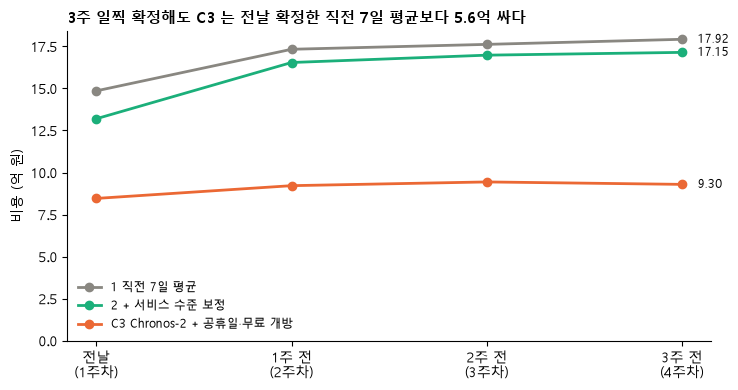

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for (m, d), col in zip(lt.groupby('방식', sort=False), [GRAY, AQUA, ORANGE]):
    ax.plot(range(4), d['비용(억)'], marker='o', color=col, lw=2, label=m)
    ax.text(3.08, d['비용(억)'].iloc[-1], f"{d['비용(억)'].iloc[-1]:.2f}", va='center', fontsize=8.5)
ax.set_xticks(range(4), [f'{l}\n({i + 1}주차)' for i, l in enumerate(LEADS)]); ax.set_ylabel('비용 (억 원)')
ax.set_ylim(0, None); ax.legend(frameon=False, fontsize=8.5, loc='lower left')
ax.set_title('3주 일찍 확정해도 C3 는 전날 확정한 직전 7일 평균보다 5.6억 싸다', loc='left', fontweight='bold', fontsize=10.5)
plt.tight_layout(); plt.show()

## 3. 가정 바꾸기 — 23개소 합계

① q0.9 로 배치 ② 무료 개방일만 부족 손해 120만(→ 무료일 τ 0.89, q0.9) ③ 1명당 1,500명.

In [5]:
S = pd.read_csv(DATA / 'scenarios.csv')
tot = S[S['개소'] == '합계']
pd.concat({'비용(억)': tot.pivot(index='가정', columns='방식', values='비용') / 1e8,
           '절감(억)': tot.pivot(index='가정', columns='방식', values='직전 7일 평균 대비 절감') / 1e8,
           '적중률': tot.pivot(index='가정', columns='방식', values='적중률')}, axis=1).round(3)

비용(억)                                             절감(억)                                               적중률                                       
방식                             1 직전 7일 평균 2 + 서비스 수준 보정 C3 Chronos-2 + 공휴일·무료 개방 1 직전 7일 평균 2 + 서비스 수준 보정 C3 Chronos-2 + 공휴일·무료 개방 1 직전 7일 평균 2 + 서비스 수준 보정 C3 Chronos-2 + 공휴일·무료 개방
가정                                                                                                                                                                                  
① 서비스 수준 0.9                       14.857        14.801                    8.879        0.0         0.056                    5.978      0.582         0.899                    0.908
② 무료 개방일만 C_u 120만 (무료일 τ 0.9)     19.761        15.414                    9.622        0.0         4.347                   10.139      0.582         0.815                    0.813
③ 1명당 1,500명                       19.809        17.599                   11.281        0.0         2.210                    8.528      0.582         0.804                    0.804
기본 (τ 0.8, C_u 60만, 2,000명)        14.857        13.199                    8.461        0.0         1.658                    6.396      0.582         0.804                    0.804

## 4. 가정 바꾸기 — 개소별 절감 (C3 vs 직전 7일 평균, 백만 원)

23개소 × 4가정 모두 양수면 결론이 가정에 흔들리지 않는다.

In [6]:
ss = S[(S['방식'] == 'C3 Chronos-2 + 공휴일·무료 개방')].pivot(index='개소', columns='가정', values='직전 7일 평균 대비 절감') / 1e6
order = ['경복궁', '창덕궁', '창경궁', '덕수궁', '종묘'] + [i for i in ss.index if i not in ('경복궁', '창덕궁', '창경궁', '덕수궁', '종묘', '합계')] + ['합계']
ss = ss.reindex(order)
print('모두 양수:', bool((ss > 0).all().all()))
ss.round(1)

모두 양수: True


가정,① 서비스 수준 0.9,② 무료 개방일만 C_u 120만 (무료일 τ 0.9),"③ 1명당 1,500명","기본 (τ 0.8, C_u 60만, 2,000명)"
개소,,,,
경복궁,204.3,391.5,285.9,214.4
창덕궁,93.5,147.5,127.5,95.6
창경궁,86.1,139.6,117.0,87.8
덕수궁,61.2,109.7,102.9,77.2
종묘,54.7,78.0,69.5,52.2
광릉,4.8,6.9,8.4,6.3
김포장릉,9.4,12.6,14.0,10.5
동구릉,6.7,10.4,11.3,8.5
사릉,0.5,0.8,0.8,0.6
